# Deconvolution

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-09.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [3]:
# ==========================================
# 1. Generate the Input Image (image03)
# ==========================================
# Replicating Mathematica: ImageClip[RandomImage[{-100, 1}, {128, 128}], {0, 1}]
# This creates a sparse image with mostly 0s and a few bright "stars"
np.random.seed(42)  # Set seed for reproducibility
raw_data = np.random.uniform(-100, 1, (128, 128))
image03 = np.clip(raw_data, 0, 1)

# ==========================================
# 2. Perform Convolution
# ==========================================
# Replicating Mathematica: ImageConvolve[..., GaussianMatrix[psfparam], ...]
# We select a static value for psfparam (sigma) here.
psf_param = 2.0 

# Scipy's gaussian_filter is equivalent to convolving with a Gaussian Matrix.
# mode='reflect' is the closest standard approximation to Mathematica's "Reversed" padding.
convolved_image = gaussian_filter(image03, sigma=psf_param, mode='reflect')

# Replicating Mathematica: ImageAdjust[...]
# Normalize the image data to the 0.0 - 1.0 range for display
img_min, img_max = convolved_image.min(), convolved_image.max()
if img_max > img_min:
    adjusted_image = (convolved_image - img_min) / (img_max - img_min)
else:
    adjusted_image = convolved_image



## Plot

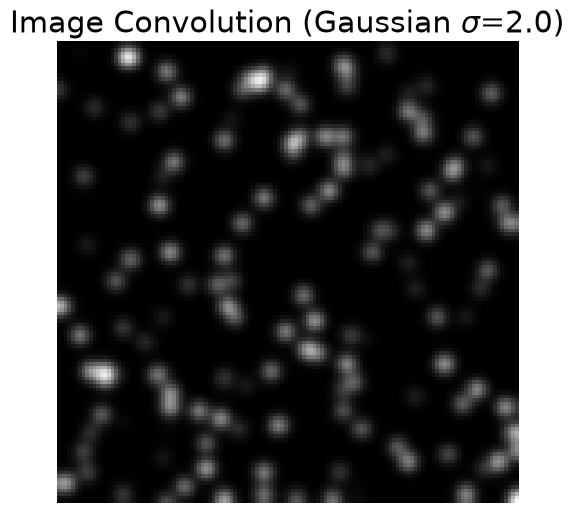

In [4]:
# ==========================================
# 3. Plotting
# ==========================================
fig1, axes1 = plt.subplots(figsize=(6, 6))

# Display the image in grayscale
axes1.imshow(adjusted_image, cmap='gray', origin='upper', vmin=0, vmax=1)
axes1.set_title(f"Image Convolution (Gaussian $\sigma$={psf_param})")
axes1.axis('off')  # Hide axis ticks/labels

plt.show()

## Make interactive with `ipywidgets`

In [5]:
# Install ipympl if not present: pip install ipympl
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, restoration
from PIL import Image, ImageDraw, ImageFont
import ipywidgets as widgets
from IPython.display import display

# Stop matplotlib from displaying the figure automatically (we will display it manually in the VBox)
plt.ioff()

# ==========================================
# 1. Image Data Generation
# ==========================================
def get_moon_image():
    try: 
        m = data.moon()
        return (m[::2, ::2] / 255.0).astype(np.float32)
    except: 
        return np.random.rand(256, 256).astype(np.float32)

def get_text_image(text="Hello Class!", size=256):
    img = Image.new('L', (size, size), color=0)
    draw = ImageDraw.Draw(img)
    try: font = ImageFont.truetype("DejaVuSans.ttf", 40)
    except: font = ImageFont.load_default()
    draw.text((20, 100), text, fill=255, font=font)
    return (np.array(img) / 255.0).astype(np.float32)

def get_sparse_random_image(size=256):
    np.random.seed(42)
    raw_data = np.random.uniform(-100, 1, (size, size))
    return np.clip(raw_data, 0, 1).astype(np.float32)

image_library = {
    "Moon": get_moon_image(),
    "Hello Class!": get_text_image(),
    "Sparse Random": get_sparse_random_image()
}

# ==========================================
# 2. Math Helpers
# ==========================================
def get_gaussian_kernel(sigma, size_factor=4):
    if sigma <= 0.1:
        k = np.zeros((3, 3)); k[1, 1] = 1.0; return k
    radius = int(sigma * size_factor)
    x, y = np.mgrid[-radius:radius+1, -radius:radius+1]
    g = np.exp(-(x**2 + y**2) / (2.0 * sigma**2))
    return g / g.sum()

# ==========================================
# 3. Setup Figure
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 5))
fig.canvas.header_visible = False
fig.canvas.layout.width = '100%' 
fig.canvas.layout.height = 'auto'

# Layout adjustments
plt.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.05, wspace=0.05)

# Constants
FIXED_BLUR_SIGMA = 3.0
kw = {'cmap': 'gray', 'vmin': 0, 'vmax': 1, 'aspect': 'equal'}

# Placeholders
img_orig = ax1.imshow(np.zeros((256,256)), **kw)
ax1.set_title("1. Original", fontsize=12)
ax1.axis('off')

img_blur = ax2.imshow(np.zeros((256,256)), **kw)
ax2.set_title(f"2. Blurred (Fixed $\sigma$={FIXED_BLUR_SIGMA})", fontsize=12)
ax2.axis('off')

img_rest = ax3.imshow(np.zeros((256,256)), **kw)
ax3.set_title("3. Result", fontsize=12)
ax3.axis('off')

# ==========================================
# 4. Controls & Logic
# ==========================================

# Widgets
w_status = widgets.Label(value="Status: Ready")

w_menu = widgets.Dropdown(
    options=["Moon", "Hello Class!", "Sparse Random"],
    value="Sparse Random",
    description="Image:",
    layout=widgets.Layout(width='200px')
)

w_slider = widgets.FloatSlider(
    value=1.0, 
    min=0, max=10.0, step=0.2, 
    description='Est. PSF:',
    layout=widgets.Layout(width='500px'),
    continuous_update=False  # MUST be False for heavy math like deconvolution
)

def on_change(change):
    # Retrieve values
    img_name = w_menu.value
    est_sigma = w_slider.value
    
    w_status.value = "Status: Calculating..."
    
    # 1. Get Data
    original = image_library[img_name]
    
    # 2. Blur (The Problem)
    blurred = gaussian_filter(original, sigma=FIXED_BLUR_SIGMA, mode='reflect')
    blurred = np.clip(blurred, 0, 1)
    
    # 3. Restore (The Solution)
    if est_sigma < 0.1:
        restored = blurred
    else:
        psf = get_gaussian_kernel(est_sigma)
        # Richardson-Lucy is computationally expensive
        restored = restoration.richardson_lucy(blurred, psf, num_iter=15, clip=False)
        restored = np.clip(restored, 0, 1)

    # 4. Update Visualization
    img_orig.set_data(original)
    img_blur.set_data(blurred)
    img_rest.set_data(restored)
    
    status_txt = ""
    if abs(est_sigma - FIXED_BLUR_SIGMA) < 0.2: status_txt = " (MATCH)"
    elif est_sigma > FIXED_BLUR_SIGMA + 1.0: status_txt = " (RINGING)"
    
    ax3.set_title(f"3. Result (Est $\sigma$={est_sigma}){status_txt}", fontsize=12)
    
    fig.canvas.draw_idle()
    w_status.value = "Status: Ready"

# Link events
w_menu.observe(on_change, names='value')
w_slider.observe(on_change, names='value')

# Trigger initial update
on_change(None)

# ==========================================
# 5. Display Layout
# ==========================================
controls = widgets.HBox(
    [w_menu, w_slider, w_status],
    layout=widgets.Layout(align_items='center', justify_content='center', margin='10px')
)

# Bundle everything into one VBox container
app = widgets.VBox([controls, fig.canvas])
display(app)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-09_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-09.html) (direct link: [ch05-09_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-09_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.